# Outlier detection

**Author:** Mio Diaz

**Purpose:** Mid-Report 2 

**Section 3: Outlier Detection**.

The assignment asks for all of the following:

| # | Assignment item | Where in this notebook |
|---|---|---|
| a | Apply at least two outlier detection methods | §4 DBSCAN, §5 One-Class SVM |
| b | Clearly define what an "outlier" is in our project context | §2 |
| c | Visualize detected outliers and explain their characteristics | §6, §7 |
| d | Discuss potential causes (data errors, rare but valid cases, automation, ...) | §8 |
| e | Evaluate the impact of outliers on clustering and dimensionality reduction | §9 |
| — | Robustness of the definition (not required) | §10 |
| — | Feed Section 4 (integration, insights, limitations) | §11 |

**Data:** Table A (`data/merged_dataset.csv`, 62,627 repos × 49 columns), 2024 GH Archive activity only. `inactive_next_365d` (2025) is never a feature; it is only used to *check* the outliers afterwards.

## Thought process at a glance

1. **What is normal?** (§2) The full dataset is dominated by tiny one-burst repos, so "normal" there would mean "never maintained". We narrow to **real projects** (active in ≥ 3 months of 2024, 7,890 repos), where the dense middle is a consistently maintained project.
2. **What is an outlier?** (§2) A real project far from that middle, in either direction: **low side** = went quiet (decaying), **high side** = abnormal volume (automation, bots, mirrors, or a very large project).
3. **How do we measure "far"?** (§3) Log-transformed, standardized 2024 activity features, including first-half vs second-half activity so a project that went quiet looks different from a steady one.
4. **Two methods, two ideas of "far"** (§4–5): **DBSCAN** (Lesson 11, *not near any dense group*) and **One-Class SVM** (Lesson 12, *outside the learned boundary of normal*). Both are required by the assignment (≥ 2 methods); we picked two that work differently so agreement means something.
5. **Do they agree, and which side are the outliers on?** (§6) Robust z-scores tag each outlier low or high side.
6. **What are they, and does the definition hold?** (§7–8) Look at them, then check: low-side outliers should go inactive in 2025 more often than the 47% base rate.
7. **Do outliers change the patterns?** (§9) Clustering and PCA with vs without outliers.
8. **Does it depend on our cutoff?** (§10) Rerun on projects active ≥ 6 months.

**Scope decisions:** methods come from the course lessons only. GMM (12.3) and VAE (12.4) are left out (two methods are required; VAE needs PyTorch), and the packaged-projects analysis with deps.dev features is a next step (§11).

## 0. Dependencies on teammates

Section 3 can start on its own; only §9 (impact on clustering / DR) depends on the other sections. To keep the three sections consistent, send the clustering and DR owners:

- **population:** repos with `active_months_2024 >= 3` (7,890 repos);
- **features:** `FEATURES` from §1 (log1p activity counts, H1 / H2 qualifying events, days since last push), then `StandardScaler`;
- coverage flags and `inactive_next_365d` are **not** features.

**Open questions:**
- [ ] Clustering: which algorithms, which `k` / `eps` / `minPts`; same population and features?
- [ ] DR: PCA components kept, t-SNE / UMAP params; same population and features?
- [ ] If the clustering owner also uses DBSCAN, agree on `eps` / `minPts` so §4 and their section don't contradict each other (their noise points = our DBSCAN outliers).
- [ ] Do they want the outlier flags exported (`is_outlier`) so they can rerun without outliers?

Until answers come back, §9 uses a **baseline K-means + PCA** whose settings sit in one block that can be swapped for theirs.

**Notes:**

- **Assignment item:** (coordination) dependencies and shared settings
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 1. Setup: imports, shared constants and helpers

Everything reused later lives here, so each later cell only contains the step it is about:
- **feature groups** (`VOLUME`, `BREADTH`, `TREND`, `RECENCY`) — the single source of truth for which columns are used;
- **`real_projects(df, min_months)`** — the population filter, reused for the ≥ 6-month robustness check;
- **`build_features(df)`** — log1p + fill + standardize, reused by every method and by §9–10;
- **`describe(df)`** — the descriptive statistics table;
- **`style(ax)` / `save_fig(fig, name)`** — one plot style; figures go to `figures/` (SVG) and `report/img/` (PNG).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

DATA = Path("../data")
FIG_DIR = Path("../figures")
REPORT_IMG = Path("../report/img")
REPORT_IMG.mkdir(parents=True, exist_ok=True)

# Plot palette: one main hue, one highlight, recessive ink and grid.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"

# Feature groups (2024 GH Archive only). Single source of truth for every later step.
VOLUME = ["push_events_2024", "issue_events_2024", "issue_comment_events_2024", "pull_request_events_2024",
          "review_events_2024", "release_events_2024", "stars_received_2024", "fork_events_2024"]
BREADTH = ["distinct_actors_2024", "active_days_2024", "active_months_2024"]
TREND = ["qualifying_events_h1_2024", "qualifying_events_h2_2024"]   # separate counts: the H2/H1 ratio is undefined when H1 = 0
RECENCY = ["days_since_last_push_at_cutoff"]                         # NaN = no push in 2024 -> 366
FEATURES = VOLUME + BREADTH + TREND + RECENCY
COUNTS = VOLUME + BREADTH + TREND                                    # columns that get log1p
LABEL = "inactive_next_365d"                                         # validation only, never a feature
MIN_MONTHS = 3                                                       # "real project" cutoff (§2e)


def real_projects(df, min_months=MIN_MONTHS):
    """Repos active in at least `min_months` separate months of 2024."""
    return df[df["active_months_2024"] >= min_months].copy()


def build_features(df):
    """log1p on counts, NaN days-since-push -> 366, then standardize. Returns a DataFrame aligned to df.index."""
    raw = df[FEATURES].copy()
    raw[COUNTS] = np.log1p(raw[COUNTS])
    raw[RECENCY] = raw[RECENCY].fillna(366)
    return pd.DataFrame(StandardScaler().fit_transform(raw), index=df.index, columns=FEATURES)


def describe(df, quantiles=(0.01, 0.25, 0.5, 0.75, 0.99)):
    """Descriptive statistics: mean, chosen quantiles, max, % zero, skew."""
    t = pd.DataFrame({"mean": df.mean()})
    for q in quantiles:
        t["median" if q == 0.5 else f"p{round(q * 100)}"] = df.quantile(q)
    t["max"] = df.max()
    t["% zero"] = (df == 0).mean() * 100
    t["skew"] = df.skew()
    return t.round(2)


def style(ax, grid="y"):
    """Recessive axes: no top/right spines, light grid on one axis, muted ticks."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def title(ax, text):
    ax.set_title(text, loc="left", fontsize=10, color=INK)


def save_fig(fig, name):
    """figures/<name>.svg (no timestamp -> clean diffs) and report/img/<name>.png."""
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight", metadata={"Date": None})
    fig.savefig(REPORT_IMG / f"{name}.png", bbox_inches="tight", dpi=150)


A = pd.read_csv(DATA / "merged_dataset.csv")
print(f"Table A: {len(A):,} repos x {A.shape[1]} columns | {len(FEATURES)} features")

Table A: 62,627 repos x 49 columns | 14 features


## 2. What counts as normal, and what counts as an outlier

**Question:** Before calling anything abnormal, what does a normal repo look like — and is that the right reference for *maintained*?

**Approach:**
- 2a–2c: describe the **full population** and show why it can't be the reference.
- 2d: decide where a **real project** starts (active months).
- 2e: describe the **real-project population**; its dense middle is *normal*.
- 2f: write the definition.

### 2a. The full population: descriptive statistics

In [2]:
describe(A[VOLUME + BREADTH + RECENCY], quantiles=(0.5, 0.75, 0.9, 0.99))

,mean,median,p75,p90,p99,max,% zero,skew
push_events_2024,43.77,3.0,14.0,35.0,301.00,362071.0,1.91,136.80
issue_events_2024,1.61,0.0,0.0,0.0,13.00,51240.0,95.41,248.46
issue_comment_events_2024,2.41,0.0,0.0,0.0,27.00,30312.0,93.83,216.38
pull_request_events_2024,3.60,0.0,0.0,2.0,67.00,6209.0,84.62,69.51
review_events_2024,2.08,0.0,0.0,0.0,15.74,9237.0,97.23,79.89
release_events_2024,0.25,0.0,0.0,0.0,4.00,361.0,97.09,45.88
stars_received_2024,1.84,0.0,0.0,0.0,12.00,8745.0,90.41,96.29
fork_events_2024,0.40,0.0,0.0,0.0,4.00,1653.0,94.88,90.32
distinct_actors_2024,1.54,1.0,1.0,2.0,7.00,1251.0,0.00,86.88
active_days_2024,6.82,1.0,4.0,12.0,103.00,366.0,0.00,9.81


### 2b. The typical repo profile

Share of repos that match each "tiny repo" condition. Most repos match most conditions, so in the full population a *tiny one-burst repo* would be "normal" and every maintained project would look like an outlier — the wrong way round for this project.

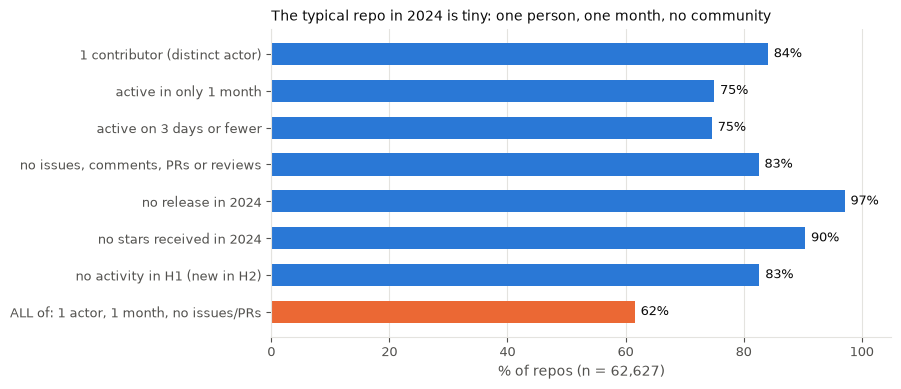

In [3]:
engagement = ["issue_events_2024", "issue_comment_events_2024", "pull_request_events_2024", "review_events_2024"]
no_engagement = A[engagement].sum(axis=1).eq(0)
one_actor, one_month = A["distinct_actors_2024"].eq(1), A["active_months_2024"].eq(1)
profile = pd.Series({
    "1 contributor (distinct actor)": one_actor.mean(),
    "active in only 1 month": one_month.mean(),
    "active on 3 days or fewer": A["active_days_2024"].le(3).mean(),
    "no issues, comments, PRs or reviews": no_engagement.mean(),
    "no release in 2024": A["release_events_2024"].eq(0).mean(),
    "no stars received in 2024": A["stars_received_2024"].eq(0).mean(),
    "no activity in H1 (new in H2)": A["h1_qualifying_events_zero"].eq(1).mean(),
    "ALL of: 1 actor, 1 month, no issues/PRs": (one_actor & one_month & no_engagement).mean(),
}).mul(100)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(profile.index, profile.values, color=[ORANGE] + [BLUE] * (len(profile) - 1), height=0.6)
for y, v in enumerate(profile.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set(xlim=(0, 105))
ax.set_xlabel(f"% of repos (n = {len(A):,})", color=MUTED)
title(ax, "The typical repo in 2024 is tiny: one person, one month, no community")
style(ax, grid="x")
save_fig(fig, "outliers_normal_profile")
plt.show()

### 2c. Why everything is log-transformed

Raw counts are so skewed that a histogram is one bar at zero; on a `log1p` scale the shape becomes visible. Without the log, every method would just rank repos by size.

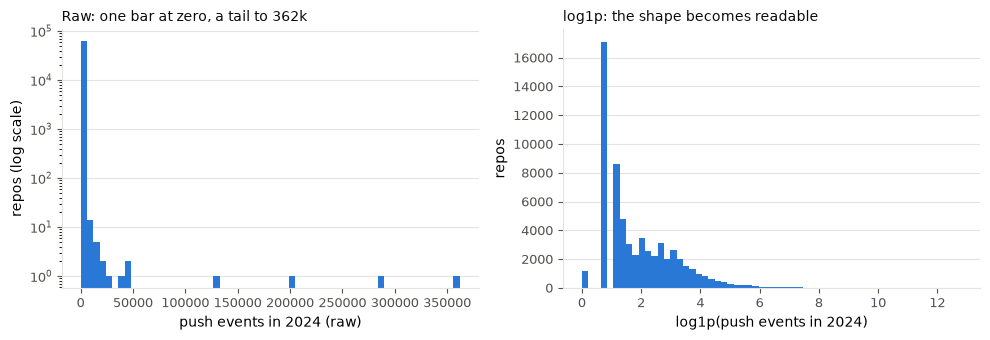

In [4]:
x = A["push_events_2024"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, values, xlabel, ylog, text in [
    (axes[0], x, "push events in 2024 (raw)", True, "Raw: one bar at zero, a tail to 362k"),
    (axes[1], np.log1p(x), "log1p(push events in 2024)", False, "log1p: the shape becomes readable"),
]:
    ax.hist(values, bins=60, color=BLUE)
    ax.set(xlabel=xlabel, ylabel="repos (log scale)" if ylog else "repos", yscale="log" if ylog else "linear")
    title(ax, text)
    style(ax)
fig.tight_layout()
save_fig(fig, "outliers_push_raw_vs_log")
plt.show()

### 2d. Where a "real project" starts

Repos and their 2025 inactivity rate by number of active months in 2024. The cutoff is set on domain grounds ("someone came back to it in at least 3 separate months"); the label is only shown to describe the groups, not to tune the cutoff.

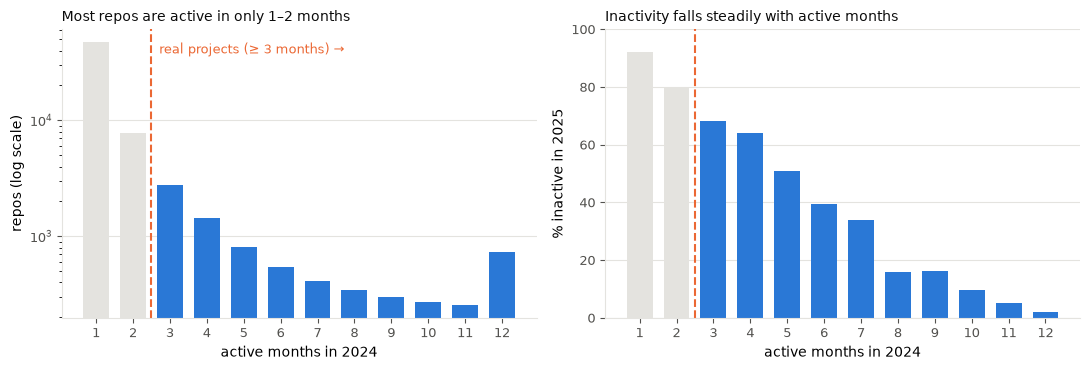

active_months_2024,1,2,3,4,5,6,7,8,9,10,11,12
repos,46973.00,7764.0,2775.00,1453.00,807.00,540.0,408.00,348.00,297.00,271.0,257.00,734.00
inactive_rate,0.92,0.8,0.68,0.64,0.51,0.4,0.34,0.16,0.16,0.1,0.05,0.02


In [5]:
by_month = A.groupby("active_months_2024")[LABEL].agg(repos="size", inactive_rate="mean")
months = by_month.index.to_numpy()
colors = np.where(months >= MIN_MONTHS, BLUE, GRID)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, values, ylabel, text in [
    (axes[0], by_month["repos"], "repos (log scale)", "Most repos are active in only 1–2 months"),
    (axes[1], by_month["inactive_rate"] * 100, "% inactive in 2025", "Inactivity falls steadily with active months"),
]:
    ax.bar(months, values, color=colors, width=0.7)
    ax.set(xlabel="active months in 2024", ylabel=ylabel, xticks=months)
    ax.axvline(MIN_MONTHS - 0.5, color=ORANGE, linestyle="--", linewidth=1.5)
    title(ax, text)
    style(ax)
axes[0].set_yscale("log")
axes[1].set_ylim(0, 100)
axes[0].text(MIN_MONTHS - 0.4, by_month["repos"].max(), f" real projects (≥ {MIN_MONTHS} months) →", color=ORANGE, fontsize=9, va="top")
fig.tight_layout()
save_fig(fig, "outliers_population_cutoff")
plt.show()
by_month.round(2).T

### 2e. The real-project population

Population split, then the same descriptive statistics within real projects. Here the middle of the distribution is a consistently maintained repo, and both tails are visible.

In [6]:
P = real_projects(A)
group = np.select([A["active_months_2024"] >= 6, A["active_months_2024"] >= MIN_MONTHS],
                  ["real project, ≥ 6 months (robustness set, §10)", "real project, 3–5 months"],
                  default="one-burst repo, 1–2 months (excluded)")
split = A.groupby(group)[LABEL].agg(repos="size", inactive_rate="mean")
split["% of repos"] = split["repos"] / len(A) * 100
display(split.round(2))
print(f"Real-project population P: {len(P):,} repos ({len(P) / len(A):.1%}), inactive rate {P[LABEL].mean():.2f}")
describe(P[FEATURES])

,repos,inactive_rate,% of repos
"one-burst repo, 1–2 months (excluded)",54737,0.90,87.40
"real project, 3–5 months",5035,0.64,8.04
"real project, ≥ 6 months (robustness set, §10)",2855,0.18,4.56


Real-project population P: 7,890 repos (12.6%), inactive rate 0.47


,mean,p1,p25,median,p75,p99,max,% zero,skew
push_events_2024,214.05,0.89,19.0,37.0,83.00,1781.44,362071.0,1.00,71.93
issue_events_2024,11.74,0.00,0.0,0.0,0.00,111.33,51240.0,81.90,88.22
issue_comment_events_2024,18.09,0.00,0.0,0.0,1.00,289.11,30312.0,72.86,77.06
pull_request_events_2024,22.78,0.00,0.0,0.0,10.00,385.55,6209.0,59.10,25.84
review_events_2024,15.40,0.00,0.0,0.0,0.00,276.11,9237.0,86.89,28.77
release_events_2024,1.62,0.00,0.0,0.0,0.00,28.00,361.0,88.95,16.93
stars_received_2024,12.68,0.00,0.0,0.0,1.00,233.11,8745.0,71.80,34.80
fork_events_2024,2.54,0.00,0.0,0.0,0.00,45.00,1653.0,81.10,34.71
distinct_actors_2024,4.08,1.00,1.0,1.0,2.75,44.00,1251.0,0.00,31.53
active_days_2024,38.37,3.00,9.0,17.0,34.00,365.00,366.0,0.00,3.53


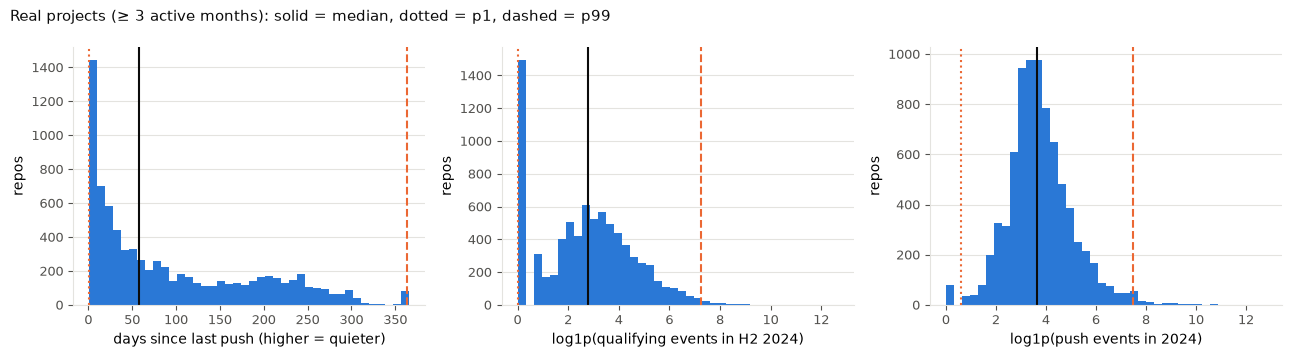

In [7]:
# Both tails inside the real-project population: low side (went quiet) and high side (huge volume).
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, xlabel in [
    (axes[0], "days_since_last_push_at_cutoff", "days since last push (higher = quieter)"),
    (axes[1], "qualifying_events_h2_2024", "log1p(qualifying events in H2 2024)"),
    (axes[2], "push_events_2024", "log1p(push events in 2024)"),
]:
    v = P[col].fillna(366)
    v = v if col in RECENCY else np.log1p(v)
    ax.hist(v, bins=40, color=BLUE)
    for q, ls, color in [(0.01, ":", ORANGE), (0.5, "-", INK), (0.99, "--", ORANGE)]:
        ax.axvline(v.quantile(q), color=color, linestyle=ls, linewidth=1.5)
    ax.set(xlabel=xlabel, ylabel="repos")
    style(ax)
fig.suptitle(f"Real projects (≥ {MIN_MONTHS} active months): solid = median, dotted = p1, dashed = p99",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
save_fig(fig, "outliers_project_tails")
plt.show()

### 2f. Definition

> **Within real projects (≥ 3 active months in 2024), an outlier is a repo whose 2024 activity profile is far from the consistently-maintained middle, on the log scale, in either direction.**
>
> - **Low-side outliers (decaying):** the project was active and then went quiet — few or no events in H2, a long time since the last push.
> - **High-side outliers (abnormal volume):** activity far beyond what maintenance needs — automation, bots, mirrors, daily auto-updates — or, rarely, a very large community project.

- **Type (Lesson 11.2):** mostly **global** outliers within the population; groups of near-identical bot repos may be **collective** outliers.
- **Expected share:** about 1% (One-Class SVM `nu = 0.01`); DBSCAN's share follows from `eps` (§4).
- **Validation (not used for detection):** low-side outliers should go inactive in 2025 well above the population's 47%; high-side outliers should not.

**Notes:**

- **Assignment item:** Outlier Detection → clearly define what constitutes an outlier in your project context
- **What it shows:**
  - **Full population (2a–2c):** the median repo in 2024 has 3 pushes, 1 contributor, 1 active day and 1 active month, and no issues, PRs, reviews, releases or stars. 84% have a single contributor, 75% were active in only one month, 62% match *all* of: 1 actor, 1 month, no issues/PRs. Counts are extremely right-skewed (skew 46–248; pushes: mean 43.8, median 3, p99 301, max 362,071).
  - **Population cutoff (2d):** 2025 inactivity falls steadily with active months: 92% at 1 month, 68% at 3, 40% at 6, 2% at 12.
  - **Real projects (2e):** 7,890 repos (12.6%) with ≥ 3 active months; 47% went inactive in 2025 (vs 90% for one-burst repos and 18% for ≥ 6 months).
  - The median real project: 37 pushes, 4 active months, 17 active days, 26 qualifying events in H1 and 15 in H2, last push 58 days before the cutoff. Still usually **one contributor** (median 1, p75 ≈ 3): "maintained" here mostly means a solo maintainer who keeps coming back.
  - Both tails exist: p1 of pushes is ~1 and 19% of projects had **no** qualifying events in H2 (low side), while p99 of pushes is ~1,780 against a max of 362,071 (high side).
  - **Automation already visible:** 98 repos were active on 360+ days of 2024, 62% with a single contributor and a median of ~1,500 pushes. Names are mostly profile READMEs (`owner/owner`, auto-updated daily by GitHub Actions), scrapers (`cv-arxiv-daily`, `v2free`) and bots (`tiktokbot`): activity without maintenance, i.e. the high-side outlier type.
- **Notes for the report:**
  - Using the full population would make a tiny one-burst repo "normal" and every maintained project an outlier, which is the opposite of what this project needs. So outliers are detected among real projects, and the one-burst repos (87%) are reported as a separate, never-maintained group.
  - *Normal* = a consistently maintained project. *Outliers* = far from it in either direction: low side = decaying, high side = automation or exceptionally large projects.
  - The 2025 label is not used to detect outliers, only to check that low-side outliers really do go inactive more often (validation of the definition).
  - The log transform is required: on raw counts every method would just rank repos by size.


## 3. Feature matrix

**Question:** How do we turn each real project into a point, so that "far from normal" can be measured?

**Approach:**
- Population `P` from §2 (7,890 repos).
- `build_features` from §1: `log1p` on counts (§2c), days since last push with NaN → 366, `StandardScaler` so no feature dominates by its units.
- **H1 and H2 events as separate features**, so a project that went quiet (high H1, low H2) is far from a steady one even with the same yearly total.
- **Not features:** identifiers; deps.dev / Scorecard values (98–100% missing); coverage flags like `has_package` (a rare 1 would standardize to z ≈ 8 and dominate distances); the 2025 label.

In [8]:
X = build_features(P)
y = P[LABEL]

assert not X.isna().any().any(), "NaN in feature matrix"
assert LABEL not in X.columns and "has_package" not in X.columns
print(f"X: {X.shape[0]:,} real projects x {X.shape[1]} features")
X.describe().loc[["mean", "std", "min", "max"]].round(2)

X: 7,890 real projects x 14 features


,push_events_2024,issue_events_2024,issue_comment_events_2024,pull_request_events_2024,review_events_2024,release_events_2024,stars_received_2024,fork_events_2024,distinct_actors_2024,active_days_2024,active_months_2024,qualifying_events_h1_2024,qualifying_events_h2_2024,days_since_last_push_at_cutoff
mean,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.86,-0.40,-0.50,-0.71,-0.33,-0.30,-0.45,-0.38,-0.60,-1.66,-0.99,-1.40,-1.42,-1.02
max,6.92,9.99,7.05,4.52,7.46,8.17,7.66,9.43,8.99,2.86,1.87,3.93,5.24,2.90


**Notes:**

- **Assignment item:** Outlier Detection → data used for detection; population filter; excluded columns and why
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 4. Method 1: DBSCAN noise points (Lesson 11.4, distance / density based)

**Question:** Which projects are not close to any dense group of projects?

**Approach:**
- DBSCAN groups points that have at least `min_samples` neighbours within `eps`; points that belong to no group are labelled `-1` (**noise = outlier**).
- `min_samples` ≈ 2 × number of features (rule of thumb from the lesson).
- `eps` from the **k-distance plot**: sort every point's distance to its `min_samples`-th neighbour and take the knee.
- Small sensitivity table: how the number of outliers changes with `eps`.
- The fit is wrapped in `dbscan_outliers(X, eps, min_samples)` so §10 can reuse it.

In [9]:
# TODO: k-distance plot -> choose EPS; MIN_SAMPLES = 2 * X.shape[1]

In [10]:
# TODO:
# def dbscan_outliers(X, eps, min_samples):
#     """True where DBSCAN labels the point as noise (-1)."""
# flags["dbscan"] = dbscan_outliers(X, EPS, MIN_SAMPLES); eps sensitivity table

**Notes:**

- **Assignment item:** Outlier Detection → apply at least two methods (method 1: DBSCAN)
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 5. Method 2: One-Class SVM (Lesson 12.2, classification / boundary based)

**Question:** Which projects fall outside the learned boundary of a *normal* maintained project?

**Approach:**
- One-Class SVM learns a boundary around the bulk of the data without any labels; points outside it are outliers.
- RBF kernel (the boundary can be curved), `gamma="scale"`, `nu = 0.01` ≈ upper bound on the share of outliers (§2f).
- 7,890 rows is small enough to fit on the whole population.
- Decision-score histogram with the cutoff marked.
- The fit is wrapped in `ocsvm_outliers(X, nu)` so §10 can reuse it.

In [11]:
# TODO:
# def ocsvm_outliers(X, nu=0.01):
#     """True where the One-Class SVM decision function is negative (outside the boundary)."""
# flags["ocsvm"] = ocsvm_outliers(X); decision-score histogram

**Notes:**

- **Assignment item:** Outlier Detection → apply at least two methods (method 2: One-Class SVM)
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 6. Do the two methods agree, and on which side are the outliers?

**Question:** Which repos are outliers under both ideas of "far", and are they low side (decaying) or high side (abnormal volume)?

**Approach:**
- 2 × 2 overlap table and Jaccard similarity of the two flag sets.
- **Consensus outliers** = flagged by both methods (the robust set used in §7–9).
- **Side:** mean robust z-score (median / MAD) over the volume features: negative = low side, positive = high side. Also the single feature with the largest |z|, so each outlier can be explained in words.
- Table of the most extreme consensus outliers on each side with repo names.

In [12]:
# TODO: overlap table, Jaccard, flags['consensus'], side tag, top outliers per side

**Notes:**

- **Assignment item:** Outlier Detection → compare methods; which repos are robustly anomalous; low vs high side
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 7. Visualizing the outliers and checking the definition

**Question:** What do the outliers look like compared with normal projects — and do low-side outliers really decay?

**Approach:**
- PCA 2-D scatter of `X`, inliers in grey, low- and high-side outliers highlighted.
- Key features (pushes, H1 vs H2 events, days since last push, actors): inliers vs low side vs high side.
- **Validation:** 2025 inactivity rate for inliers vs low side vs high side, against the 47% base rate.

In [13]:
# TODO: PCA scatter with outliers highlighted

In [14]:
# TODO: feature comparison by group + inactive rate by group

**Notes:**

- **Assignment item:** Outlier Detection → visualize detected outliers and explain their characteristics
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 8. Potential causes

**Question:** Why are these repos outliers — real behaviour, automation, or data problems?

**Approach:**
- Read the names and profiles of the top consensus outliers on each side.
- Low side: **decaying / abandoned** (maintainer left, project finished), **moved or renamed** (activity continued elsewhere), **seasonal** (course or event projects).
- High side: **automation / bot**, **mirror / generated**, **rare but valid (large community project)**.
- Either side: **data artifact** (duplicate name, collection gap).
- Count per cause.

In [15]:
# TODO: top outliers per side with names + assigned cause, counts per cause

**Notes:**

- **Assignment item:** Outlier Detection → discuss potential causes of these anomalies
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 9. Impact on clustering and dimensionality reduction

**Question:** If we keep vs remove the consensus outliers, do the clusters and the PCA picture change?

**Approach:**
- Baseline until teammates' settings are known: K-means (`K` by silhouette on `X`) and PCA, on the same `X`.
- Fit **with** and **without** consensus outliers and compare: PCA explained variance and loadings; cluster sizes, silhouette, centroid shift; Adjusted Rand Index on the shared inliers.
- Before / after figures.

In [16]:
# === Settings to replace with teammates' choices ===
K = None          # TODO: number of clusters (silhouette, or the clustering owner's k)
N_COMPONENTS = 2  # PCA components for plotting
# ====================================================
# TODO: fit K-means + PCA with / without consensus outliers, compare metrics

In [17]:
# TODO: before / after figures

**Notes:**

- **Assignment item:** Outlier Detection → evaluate the impact of outliers on clustering and dimensionality reduction
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 10. Robustness: a stricter population

**Question:** Does the result depend on where we drew the "real project" line?

**Approach:**
- Rerun the same pipeline on projects active ≥ 6 months (2,855 repos, 18% inactive): `build_features(real_projects(A, 6))` → `dbscan_outliers` / `ocsvm_outliers`.
- Compare: share of outliers, low / high split, and whether low-side outliers still go inactive more often than that population's base rate.

In [18]:
# TODO: X6 = build_features(real_projects(A, 6)); rerun both methods; comparison table vs §6–7

**Notes:**

- **Assignment item:** (robustness, not required) does the outlier definition hold for a stricter population?
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 11. Summary for the report

Report-ready bullets for Section 3, plus inputs for Section 4 (integration, insights, limitations, next steps).

**Notes:**

- **Outlier definition:** _TODO_
- **Methods and agreement:** _TODO_
- **Characteristics and causes:** _TODO_
- **Validation (2025 inactivity by side):** _TODO_
- **Impact on clustering / DR:** _TODO_
- **Robustness (≥ 6 months):** _TODO_
- **Actionable insight:** _TODO_
- **Limitations / next steps:** one-burst repos excluded by design; only two methods (GMM / VAE not run); packaged projects with deps.dev features not yet analysed; _TODO_
